# 04 · Policy Gradients: REINFORCE, from CartPole to a tiny GPT

**Who this is for:** you have seen MDPs, returns and value functions (notebook 00) and know PyTorch. In
notebooks 02-03 we learned a *value* function and acted greedily on it. Here we flip the approach: we
**optimise the policy directly** with gradient ascent. This is the single most important idea for LLM RL,
because PPO-RLHF, GRPO, RLOO, DAPO, ... are all *policy-gradient* methods.

By the end you will be able to:

1. derive the **policy-gradient theorem** with the log-derivative trick, line by line;
2. implement **REINFORCE** (Williams, 1992) from scratch, plus its two variance-reduction fixes,
   **reward-to-go** and **baselines**, and *measure* how much variance each removes;
3. build a **tiny GPT from scratch** and see that text generation is a policy in a token MDP;
4. train that GPT with REINFORCE on a verifiable task (addition) and watch its next-token distribution move
   toward the correct answer.

```mermaid
flowchart LR
    N00[00 Foundations] --> N01[01 Bandits]
    N01 --> N02[02 Tabular TD / Q-learning]
    N02 --> N03[03 DQN]
    N02 --> N04["<b>04 Policy gradient</b><br/>REINFORCE<br/>(you are here)"]:::here
    N04 --> N05[05 Actor-critic, GAE]
    N05 --> N06[06 TRPO / PPO]
    N06 --> N07[07 RLHF]
    N07 --> N08[08 DPO family]
    N07 --> N09[09 GRPO family]
    N09 --> N10[10 Reasoning RLVR]
    N08 --> N11[11 RLAIF / self-play]
    N09 --> N12[12 RL for VLMs]
    N10 --> N13[13 Frontier & pitfalls]
    classDef here fill:#2563eb,color:#fff,stroke:#1e3a8a
```

## 1. Why optimise the policy directly?

Value-based methods (Q-learning, DQN) learn $Q(s,a)$ and then act with $\arg\max_a Q(s,a)$. That is awkward
for language models:

| Value-based (DQN) | Policy-based (REINFORCE, PPO, GRPO) |
|---|---|
| needs $\arg\max$ over all actions: fine for 2 actions, painful for a 150k-token vocabulary at every step | just **sample** from $\pi_\theta(a\mid s)$, which an LLM already does |
| deterministic greedy policy (needs $\varepsilon$-greedy hacks to explore) | naturally **stochastic**: temperature = exploration |
| learns "how good is each action" | learns "what to do" — and an LLM *is already* a policy we want to improve |
| off-policy, replay buffers, target networks | simple on-policy loop: sample → score → push up good samples |

**Analogy: a basketball coach with only a scoreboard.** The coach never tells the player the correct
wrist angle (that would be supervised learning). The player shoots many times *with some randomness*;
after each shot the coach only says "good" or "bad". The rule the player follows is: *make whatever you
just did a bit more likely if it scored above your usual, and a bit less likely if it scored below.* That
sentence **is** REINFORCE with a baseline. The rest of this notebook makes it precise.

## 2. The objective

A **stochastic policy** $\pi_\theta(a\mid s)$ is a neural network with parameters $\theta$ that outputs a
probability distribution over actions. Running it in the environment produces a trajectory

$$\tau = (s_0, a_0, r_1, s_1, a_1, r_2, \dots, s_{T-1}, a_{T-1}, r_T).$$

The probability of a whole trajectory factorises into *policy* terms (which depend on $\theta$) and
*environment* terms (which do not):

$$p_\theta(\tau) = \rho(s_0)\prod_{t=0}^{T-1} \underbrace{\pi_\theta(a_t\mid s_t)}_{\text{we control}}\;\underbrace{P(s_{t+1}\mid s_t,a_t)}_{\text{physics / the world}}.$$

We want to maximise the **expected return**

$$J(\theta) = \mathbb{E}_{\tau\sim p_\theta}\big[R(\tau)\big], \qquad R(\tau) = \sum_{t=0}^{T-1}\gamma^t r_{t+1}.$$

The difficulty: $\theta$ appears in the *distribution we sample from*, not inside $R$. We cannot
backpropagate through "the environment" or through a discrete sample. The log-derivative trick removes that
obstacle.

## 3. Deriving the policy-gradient theorem, step by step

**Step 1 - write the expectation as an integral (sum) over trajectories.**
$$\nabla_\theta J = \nabla_\theta \int p_\theta(\tau)\,R(\tau)\,d\tau = \int \nabla_\theta p_\theta(\tau)\,R(\tau)\,d\tau .$$

**Step 2 - the log-derivative trick.** For any positive function, $\nabla_\theta p = p\,\nabla_\theta \log p$
(because $\nabla \log p = \nabla p / p$). Substituting:
$$\nabla_\theta J = \int p_\theta(\tau)\,\nabla_\theta \log p_\theta(\tau)\,R(\tau)\,d\tau = \mathbb{E}_{\tau\sim p_\theta}\big[\nabla_\theta \log p_\theta(\tau)\,R(\tau)\big].$$
It is an expectation again, so we can estimate it by **sampling** trajectories. That is the whole trick.

**Step 3 - the environment drops out.** Take the log of the factorised trajectory probability:
$$\log p_\theta(\tau) = \log\rho(s_0) + \sum_t \log\pi_\theta(a_t\mid s_t) + \sum_t \log P(s_{t+1}\mid s_t,a_t).$$
Only the middle sum depends on $\theta$, so
$$\nabla_\theta \log p_\theta(\tau) = \sum_{t=0}^{T-1} \nabla_\theta \log \pi_\theta(a_t\mid s_t).$$
We **never need a model of the environment**, which matters for LLMs: the "environment" may be a human, a
reward model or a unit-test runner.

**Step 4 - the REINFORCE estimator.** With $N$ sampled trajectories,
$$\boxed{\;\nabla_\theta J \approx \frac1N\sum_{i=1}^N \Big(\sum_{t} \nabla_\theta\log\pi_\theta(a^i_t\mid s^i_t)\Big)\,R(\tau^i)\;}$$

**What it means:** $\nabla_\theta \log\pi_\theta(a\mid s)$ (the *score function*) is the direction in
parameter space that makes action $a$ more likely in state $s$. We take a step in that direction, weighted
by how good the trajectory was. Good trajectories are pushed up; bad ones are pushed up *less* (or, with a
baseline, pushed down).

**In code** we never form the score vectors by hand. We build a *surrogate loss* whose gradient equals the
estimator and let autograd do the rest:
$$\mathcal{L}(\theta) = -\frac1N\sum_i \sum_t \log\pi_\theta(a^i_t\mid s^i_t)\,R(\tau^i)\qquad(\text{minus because optimisers minimise}).$$
$R(\tau^i)$ is treated as a constant (no gradient flows through the reward).

### Snippet 1: the score-function estimator is unbiased (checked numerically)

Before any environment, check the core identity on the simplest possible "policy": a softmax over 3
actions with fixed rewards $r = (1, 0, 3)$. Here the exact gradient of $J(\theta) = \sum_a \pi_\theta(a)\,r_a$
is available by autograd, so we can compare it with the sampled log-derivative estimate.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import math, random, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

from rlkit.viz import COLORS, Animator, setup_style, show_frame, asset_path, save_figure, draw_box, draw_arrow, smooth

setup_style()
torch.manual_seed(0)

theta = torch.tensor([0.5, 0.0, -0.5], requires_grad=True)   # policy logits
rewards = torch.tensor([1.0, 0.0, 3.0])                       # reward of each action

# Exact gradient: J = sum_a pi(a) r(a), differentiate straight through the softmax.
J = (F.softmax(theta, -1) * rewards).sum()
exact_grad, = torch.autograd.grad(J, theta)

# Score-function (REINFORCE) estimate: sample actions, weight grad log pi(a) by r(a).
def reinforce_estimate(n_samples):
    probs = F.softmax(theta, -1)
    a = torch.multinomial(probs.detach(), n_samples, replacement=True)
    surrogate = (torch.log(probs[a]) * rewards[a]).mean()     # d/dtheta of this = estimator
    g, = torch.autograd.grad(surrogate, theta)
    return g

estimates = torch.stack([reinforce_estimate(16) for _ in range(2000)])
print("exact gradient       :", exact_grad.numpy().round(3))
print("mean of 2000 estimates:", estimates.mean(0).numpy().round(3))
print("std of one estimate   :", estimates.std(0).numpy().round(3))
assert torch.allclose(estimates.mean(0), exact_grad, atol=0.03), "REINFORCE should be unbiased"

exact gradient       : [-0.033 -0.327  0.36 ]
mean of 2000 estimates: [-0.039 -0.329  0.369]
std of one estimate   : [0.188 0.08  0.253]


The *mean* matches the exact gradient (unbiased), but a *single* estimate is noisy, with a standard deviation
comparable to the gradient itself. Variance is the central problem of policy gradients, and most of this
notebook (and the next) is about reducing it.

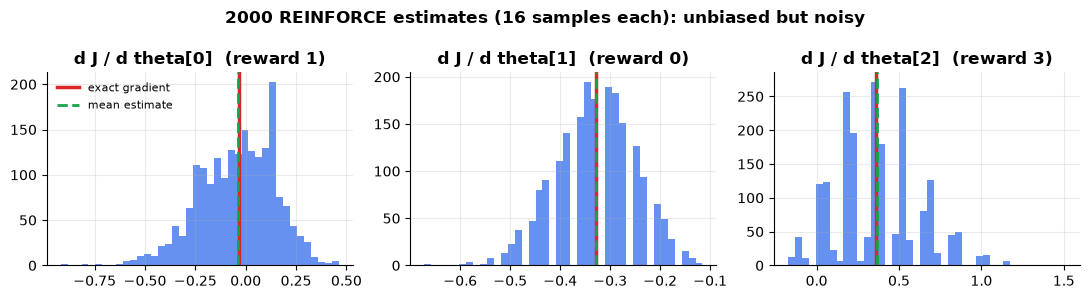

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for k, ax in enumerate(axes):
    ax.hist(estimates[:, k].numpy(), bins=40, color=COLORS["policy"], alpha=0.7)
    ax.axvline(exact_grad[k].item(), color=COLORS["penalty"], lw=2.5, label="exact gradient")
    ax.axvline(estimates[:, k].mean().item(), color=COLORS["reward"], lw=2, ls="--", label="mean estimate")
    ax.set_title(f"d J / d theta[{k}]  (reward {rewards[k]:.0f})")
axes[0].legend(fontsize=8)
fig.suptitle("2000 REINFORCE estimates (16 samples each): unbiased but noisy", fontweight="bold")
plt.tight_layout(); save_figure(fig, "04_score_function_hist.png"); plt.show()

## 4. REINFORCE: the algorithm

```mermaid
flowchart TD
    A["Initialise policy network π_θ"] --> B["Roll out N episodes with the current policy<br/>(sample actions, record log π(aₜ|sₜ) and rewards)"]
    B --> C["Compute a weight for every step<br/>R(τ) · or · reward-to-go Gₜ · or · Gₜ − b"]
    C --> D["Surrogate loss<br/>L = − mean Σₜ log π(aₜ|sₜ) · weightₜ"]
    D --> E["loss.backward(); optimizer.step()"]
    E --> F{"Good enough?"}
    F -- no --> B
    F -- yes --> G["Done"]
```

> **Algorithm: REINFORCE (Monte-Carlo policy gradient)**
>
> 1. **Initialise** a policy network $\pi_\theta$. *It outputs logits; a softmax turns them into action
>    probabilities. Random weights = a near-uniform, very exploratory policy.*
> 2. **Collect** $N$ complete episodes by *sampling* $a_t\sim\pi_\theta(\cdot\mid s_t)$. *Sampling (not argmax)
>    is essential: the estimator is an expectation over the policy's own randomness.*
> 3. **Score** each step: compute the return $R(\tau)$, or better the reward-to-go $G_t$ (§5), optionally
>    minus a baseline $b$ (§6). *This number says how much better than usual the step's consequences were.*
> 4. **Build the surrogate loss** $-\frac1N\sum_i\sum_t \log\pi_\theta(a_t\mid s_t)\,\hat A_t$ where $\hat A_t$ is
>    the weight from step 3, treated as a constant.
> 5. **Gradient step** with any optimiser (Adam here).
> 6. **Throw the data away and repeat from 2.** *REINFORCE is on-policy: the samples were drawn from the old
>    $\pi_\theta$, so after the update they no longer represent the current policy. (PPO in notebook 06 is
>    the fix that lets us reuse them a few times.)*

## 5. An environment from scratch: CartPole in pure Python

A pole is hinged on a cart; the agent pushes the cart left (action 0) or right (action 1) with a fixed
force. Reward is +1 for every time step the pole stays up (angle within ±12°, cart within ±2.4). An
episode ends when the pole falls or after 200 steps, so the maximum return is 200. The physics are the
classic Barto, Sutton & Anderson (1983) equations integrated with Euler steps of 0.02 s.

'always push right' survives 9 steps


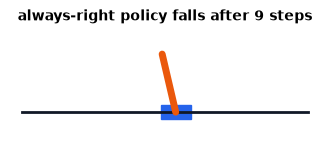

In [4]:
class CartPole:
    """Cart-pole balancing, written from scratch (no gym). State = [x, x_dot, theta, theta_dot]."""

    gravity, mass_cart, mass_pole, half_length, force_mag, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    theta_limit, x_limit = 12 * math.pi / 180, 2.4

    def __init__(self, seed=0, max_steps=200):
        self.rng = random.Random(seed)
        self.max_steps = max_steps

    def reset(self):
        self.state = [self.rng.uniform(-0.05, 0.05) for _ in range(4)]
        self.t = 0
        return list(self.state)

    def step(self, action):
        x, x_dot, th, th_dot = self.state
        force = self.force_mag if action == 1 else -self.force_mag
        total_mass = self.mass_cart + self.mass_pole
        pole_ml = self.mass_pole * self.half_length
        cos, sin = math.cos(th), math.sin(th)
        # Equations of motion for a pole on a frictionless cart.
        temp = (force + pole_ml * th_dot ** 2 * sin) / total_mass
        th_acc = (self.gravity * sin - cos * temp) / (
            self.half_length * (4.0 / 3.0 - self.mass_pole * cos ** 2 / total_mass))
        x_acc = temp - pole_ml * th_acc * cos / total_mass
        # Euler integration.
        x, x_dot = x + self.dt * x_dot, x_dot + self.dt * x_acc
        th, th_dot = th + self.dt * th_dot, th_dot + self.dt * th_acc
        self.state = [x, x_dot, th, th_dot]
        self.t += 1
        fell = abs(x) > self.x_limit or abs(th) > self.theta_limit
        return list(self.state), 1.0, fell or self.t >= self.max_steps


def draw_cartpole(ax, state, title="", color=COLORS["policy"]):
    """Draw one CartPole state on `ax` (used both for static frames and for the GIF)."""
    x, _, th, _ = state
    ax.clear(); ax.set_xlim(-2.6, 2.6); ax.set_ylim(-0.4, 1.4); ax.set_aspect("equal"); ax.axis("off")
    ax.plot([-2.4, 2.4], [0, 0], color=COLORS["ink"], lw=2)
    ax.add_patch(plt.Rectangle((x - 0.25, -0.12), 0.5, 0.24, color=color))
    tip = (x + 1.0 * math.sin(th), 1.0 * math.cos(th))
    ax.plot([x, tip[0]], [0.0, tip[1]], color=COLORS["value"], lw=5, solid_capstyle="round")
    ax.set_title(title, fontsize=10)


env = CartPole(seed=0)
s = env.reset(); steps = 0; done = False
while not done:                                     # a policy that always pushes right
    s, r, done = env.step(1); steps += 1
print(f"'always push right' survives {steps} steps")
fig, ax = plt.subplots(figsize=(4, 1.8)); draw_cartpole(ax, s, f"always-right policy falls after {steps} steps")
plt.show()

### Snippet 2: the policy network and a rollout

The policy is a 2-layer MLP: 4 state numbers in, 2 logits out. `rollout` plays one episode and keeps the
log-probability tensor of every chosen action (these carry the autograd graph we need for the update).

In [5]:
def make_cartpole_policy(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, 2))


def rollout(policy, env, record_states=False):
    """Play one episode. Returns (log_probs list[Tensor], rewards list[float], states list)."""
    s = env.reset()
    log_probs, rewards, states = [], [], [list(s)]
    done = False
    while not done:
        dist = torch.distributions.Categorical(logits=policy(torch.tensor(s)))
        a = dist.sample()                       # SAMPLE, never argmax, during training
        log_probs.append(dist.log_prob(a))      # log pi(a_t | s_t), still attached to the graph
        s, r, done = env.step(a.item())
        rewards.append(r)
        if record_states:
            states.append(list(s))
    return log_probs, rewards, states


policy = make_cartpole_policy()
lp, rw, _ = rollout(policy, CartPole(seed=1))
print(f"random policy: episode length {len(rw)}, first log-probs {[round(x.item(), 3) for x in lp[:4]]}")

random policy: episode length 25, first log-probs [-0.825, -0.793, -0.763, -0.652]


## 6. Two variance-reduction tricks (both keep the gradient unbiased)

### 6a. Reward-to-go: an action cannot affect the past

Vanilla REINFORCE multiplies every $\nabla\log\pi(a_t\mid s_t)$ by the **whole** return $R(\tau)$,
including rewards that arrived *before* $a_t$ was taken. Those earlier rewards are pure noise for that action.
One can show that the terms $\mathbb{E}[\nabla\log\pi(a_t\mid s_t)\,r_{t'}]$ with $t' \le t$ are zero
(the past reward is fixed given $s_t$, and $\mathbb{E}_{a\sim\pi}[\nabla\log\pi(a\mid s)] = 0$, proven in 6b).
Dropping them gives the **reward-to-go** estimator:

$$\nabla_\theta J \approx \frac1N\sum_i\sum_t \nabla_\theta\log\pi_\theta(a^i_t\mid s^i_t)\;G^i_t,
\qquad G_t = \sum_{t'=t}^{T-1}\gamma^{t'-t} r_{t'+1}.$$

$G_t$ is computed backwards in one pass with the recursion $G_t = r_{t+1} + \gamma\,G_{t+1}$.

### 6b. Baselines: subtract "what usually happens"

For any function $b(s_t)$ that does **not** depend on the action,

$$\mathbb{E}_{a\sim\pi_\theta}\big[\nabla_\theta\log\pi_\theta(a\mid s)\,b(s)\big]
= b(s)\sum_a \pi_\theta(a\mid s)\frac{\nabla_\theta\pi_\theta(a\mid s)}{\pi_\theta(a\mid s)}
= b(s)\,\nabla_\theta\underbrace{\sum_a\pi_\theta(a\mid s)}_{=1} = 0 .$$

So subtracting a baseline changes **nothing in expectation** but can shrink the variance a lot. Without a
baseline, when every return is positive (CartPole: always ≥ 1) *every* sampled action is pushed up and
only the relative sizes carry information. With $G_t - b$, below-average actions are pushed *down*. The
best simple choice is $b(s_t)\approx V^\pi(s_t)$, which turns the weight into an **advantage** estimate
$G_t - V(s_t)$, the starting point of actor-critic methods (notebook 05). Here we use the cheapest
baseline: the batch mean of all reward-to-go values.

In [6]:
def returns_to_go(rewards, gamma):
    """G_t = r_{t+1} + gamma * G_{t+1}, computed backwards in a single pass."""
    out, running = [], 0.0
    for r in reversed(rewards):
        running = r + gamma * running
        out.append(running)
    return out[::-1]


def step_weights(episodes, gamma, mode):
    """Per-step weights for the surrogate loss. mode in {'total', 'rtg', 'rtg_baseline'}."""
    rtg = [returns_to_go(rewards, gamma) for _, rewards in episodes]
    if mode == "total":                                    # vanilla REINFORCE: R(tau) for every step
        return [[sum(r * gamma ** t for t, r in enumerate(rewards))] * len(rewards) for _, rewards in episodes]
    if mode == "rtg":                                      # reward-to-go
        return rtg
    if mode == "rtg_baseline":                             # reward-to-go minus batch-mean baseline
        flat = [g for ep in rtg for g in ep]
        b = sum(flat) / len(flat)
        return [[g - b for g in ep] for ep in rtg]
    raise ValueError(mode)


def reinforce_loss(episodes, weights):
    """Surrogate: -mean over episodes of sum_t log pi(a_t|s_t) * weight_t (weights are constants)."""
    per_episode = [-(torch.stack(lp) * torch.tensor(w)).sum() for (lp, _), w in zip(episodes, weights)]
    return torch.stack(per_episode).mean()


print("returns_to_go([1,1,1], 0.9) =", [round(g, 3) for g in returns_to_go([1, 1, 1], 0.9)])
assert returns_to_go([1, 1, 1], 0.9) == [1 + 0.9 + 0.81, 1.9, 1.0]

returns_to_go([1,1,1], 0.9) = [2.71, 1.9, 1.0]


### Snippet 3: measuring the variance of each estimator

Fix one (random) policy, sample 300 episodes, and compute the gradient each estimator gives from **one
episode at a time**. All three have the same expectation, so the better estimator is the one whose
single-episode gradients are less spread out, i.e. agree more with the average direction.

To get one gradient per episode for three different weightings, we do not keep autograd graphs alive.
Instead we store each episode's **states and actions** and *re-score* them with the policy whenever we need
log-probabilities. This "sample once, re-score later" pattern is exactly what LLM RL does too.

In [7]:
def flat_grad(policy, loss):
    policy.zero_grad(); loss.backward()
    return torch.cat([p.grad.flatten() for p in policy.parameters()]).clone()


def rollout_sa(policy, env):
    """Play one episode without keeping graphs; return states, actions, rewards."""
    s = env.reset(); S, A, R = [], [], []; done = False
    while not done:
        with torch.no_grad():
            a = torch.distributions.Categorical(logits=policy(torch.tensor(s))).sample().item()
        S.append(s); A.append(a)
        s, r, done = env.step(a); R.append(r)
    return S, A, R


def episode_logprobs(policy, S, A):
    logp = F.log_softmax(policy(torch.tensor(S)), -1)
    return logp.gather(1, torch.tensor(A)[:, None]).squeeze(1)


torch.manual_seed(1)
probe_policy, probe_env = make_cartpole_policy(seed=3), CartPole(seed=3)
probe = [rollout_sa(probe_policy, probe_env) for _ in range(300)]
eps_for_weights = [(None, R) for _, _, R in probe]
variance_report = {}
for mode in ["total", "rtg", "rtg_baseline"]:
    w_all = step_weights(eps_for_weights, 0.99, mode)
    grads = torch.stack([flat_grad(probe_policy, -(episode_logprobs(probe_policy, S, A) * torch.tensor(w)).sum())
                         for (S, A, _), w in zip(probe, w_all)])
    mean_g = grads.mean(0)
    total_var = grads.var(0).sum().item()                       # trace of the covariance
    cos = F.cosine_similarity(grads, mean_g[None], dim=1).mean().item()
    variance_report[mode] = (total_var, cos)
    print(f"{mode:13s}  total variance {total_var:10.1f}   mean cosine(single, average) {cos:.3f}")

assert variance_report["rtg"][0] < variance_report["total"][0]
assert variance_report["rtg_baseline"][0] < variance_report["rtg"][0]

total          total variance    18090.7   mean cosine(single, average) 0.056


rtg            total variance     4929.6   mean cosine(single, average) 0.152


rtg_baseline   total variance     2573.8   mean cosine(single, average) 0.328


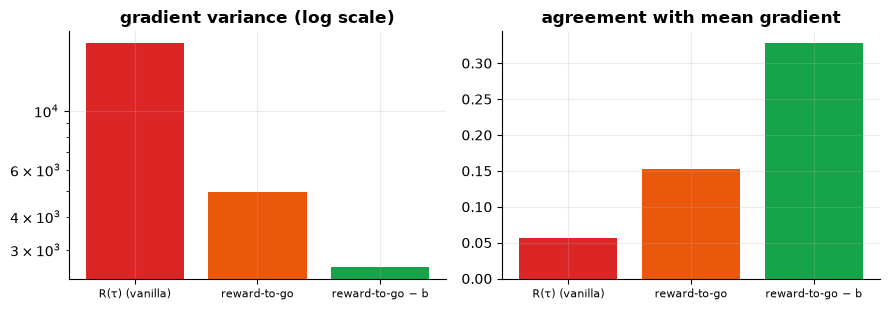

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
names = ["R(τ) (vanilla)", "reward-to-go", "reward-to-go − b"]
cols = [COLORS["penalty"], COLORS["value"], COLORS["reward"]]
vals = [v for v, _ in variance_report.values()]
axes[0].bar(names, vals, color=cols); axes[0].set_yscale("log"); axes[0].set_title("gradient variance (log scale)")
axes[1].bar(names, [c for _, c in variance_report.values()], color=cols); axes[1].set_title("agreement with mean gradient")
for ax in axes: ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); save_figure(fig, "04_variance_bars.png"); plt.show()

Same expected gradient, very different noise. Each trick removes a measurable chunk of variance, and lower
variance means each update points more reliably uphill.

## 7. Training REINFORCE on CartPole: the three variants side by side

Each iteration: sample 8 episodes, compute weights with one of the three modes, one Adam step.

In [9]:
def train_reinforce(mode, iters=60, episodes_per_iter=8, lr=1e-2, gamma=0.99, seed=0):
    policy, env = make_cartpole_policy(seed), CartPole(seed)
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    history = []
    for it in range(iters):
        episodes = [rollout(policy, env)[:2] for _ in range(episodes_per_iter)]
        loss = reinforce_loss(episodes, step_weights(episodes, gamma, mode))
        opt.zero_grad(); loss.backward(); opt.step()
        history.append(sum(len(r) for _, r in episodes) / episodes_per_iter)
    return policy, history


t0 = time.time()
results = {mode: train_reinforce(mode) for mode in ["total", "rtg", "rtg_baseline"]}
print(f"trained 3 variants in {time.time() - t0:.0f}s")
for mode, (_, h) in results.items():
    print(f"{mode:13s} mean return, first 10 iters {np.mean(h[:10]):6.1f}  last 10 iters {np.mean(h[-10:]):6.1f}")

trained 3 variants in 45s
total         mean return, first 10 iters   21.2  last 10 iters  115.5
rtg           mean return, first 10 iters   36.1  last 10 iters  182.4
rtg_baseline  mean return, first 10 iters   33.9  last 10 iters  188.3


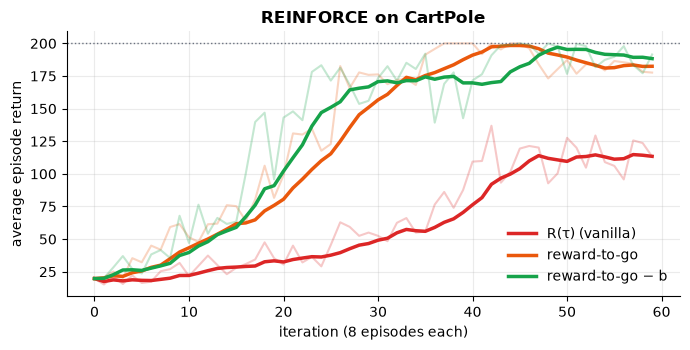

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for (mode, (_, h)), name, c in zip(results.items(), names, cols):
    ax.plot(h, color=c, alpha=0.25); ax.plot(smooth(h, 8), color=c, lw=2.5, label=name)
ax.axhline(200, color=COLORS["reference"], ls=":", lw=1); ax.set_xlabel("iteration (8 episodes each)")
ax.set_ylabel("average episode return"); ax.set_title("REINFORCE on CartPole"); ax.legend()
plt.tight_layout(); save_figure(fig, "04_cartpole_curves.png"); plt.show()

best_policy = results["rtg_baseline"][0]
assert np.mean(results["rtg_baseline"][1][-10:]) > 120, "REINFORCE + reward-to-go + baseline should balance the pole"

In our run both variance-reduced versions climb faster than vanilla REINFORCE (exact numbers are printed
above, one seed only, so treat the gap as indicative, not a benchmark).

### GIF 1: before vs after training

The same physics, the same starting distribution; left is the random initial policy, right is the policy
we just trained (sampling actions, as during training).


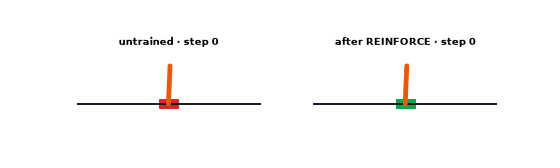

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/04_cartpole_before_after.gif')

In [11]:
def record(policy, seed):
    _, _, states = rollout(policy, CartPole(seed=seed), record_states=True)
    return states

with torch.no_grad():
    before_states = record(make_cartpole_policy(seed=0), seed=11)
    after_states = record(best_policy, seed=11)

N_FRAMES = 50
def frame_state(states, i):          # after-policy: subsample its long episode; before: freeze when fallen
    idx = min(int(i * max(len(after_states), len(before_states)) / N_FRAMES), len(states) - 1)
    return idx, states[idx]

def draw_cartpole_pair(fig, i):
    fig.clf(); a1, a2 = fig.subplots(1, 2)
    k1, s1 = frame_state(before_states, i); k2, s2 = frame_state(after_states, i)
    fallen = k1 == len(before_states) - 1
    draw_cartpole(a1, s1, f"untrained · step {k1}" + ("  ✗ fell" if fallen else ""), COLORS["penalty"])
    draw_cartpole(a2, s2, f"after REINFORCE · step {k2}", COLORS["reward"])

Animator(draw_cartpole_pair, n_frames=N_FRAMES, figsize=(8, 2.4), fps=10, dpi=70).save("04_cartpole_before_after.gif")

## 8. Part 2: a tiny GPT from scratch

Now the same algorithm on a language model. First we build the model, piece by piece. It is a standard
decoder-only transformer (GPT-2 style), only tiny: 2 layers, 4 heads, 64-dim embeddings, about 110k
parameters.

```mermaid
flowchart TD
    T["token ids (B, T)"] --> E["token embedding + position embedding<br/>(B, T, d)"]
    E --> B1["Block 1: x + Attn(LN(x)); x + MLP(LN(x))"]
    B1 --> B2["Block 2 (same)"]
    B2 --> LN["final LayerNorm"]
    LN --> H["linear head → logits (B, T, vocab)"]
    H --> S["softmax at position t = π(next token | tokens ≤ t)"]
```

**The tokenizer** maps characters to integers. Three special tokens: `<pad>`=0 (filler), `<bos>`=1
(start), `<eos>`=2 (the model's "I'm done" action).

In [12]:
from rlkit.toy_lm import CharTokenizer, TinyGPT, GPTConfig, AdditionTask, sft_train, evaluate, generate, count_parameters

tok = CharTokenizer()
ids = tok.encode("7+8=")
print("vocab size:", tok.vocab_size)
print("'7+8=' ->", ids, "->", repr(tok.decode(ids)))

vocab size: 48
'7+8=' -> [1, 10, 13, 11, 16] -> '7+8='


**Causal self-attention.** Each position builds a query $q$, key $k$ and value $v$. Position $t$ mixes the
values of positions $\le t$ with weights $\mathrm{softmax}(q_t k_j^\top/\sqrt{d_h})$. The **causal mask**
sets the weights of future positions to $-\infty$ before the softmax, so a token can never peek at the
answer it is about to predict. We write it out explicitly (rlkit uses PyTorch's fused
`scaled_dot_product_attention`, which computes the same thing).

In [13]:
class MiniCausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(d_model, 3 * d_model)   # one matmul produces q, k and v
        self.proj = nn.Linear(d_model, d_model)       # mixes the heads back together

    def forward(self, x):
        B, T, C = x.shape
        hd = C // self.n_head
        q, k, v = self.qkv(x).split(C, dim=-1)
        q, k, v = (t.view(B, T, self.n_head, hd).transpose(1, 2) for t in (q, k, v))  # (B, heads, T, hd)
        scores = q @ k.transpose(-2, -1) / math.sqrt(hd)                                # (B, heads, T, T)
        causal = torch.ones(T, T, dtype=torch.bool).tril()                             # lower triangle = allowed
        scores = scores.masked_fill(~causal, float("-inf"))
        weights = scores.softmax(dim=-1)
        y = (weights @ v).transpose(1, 2).reshape(B, T, C)
        return self.proj(y)


class MiniBlock(nn.Module):
    """Pre-norm residual block. Residuals let gradients flow straight through deep stacks."""

    def __init__(self, d_model, n_head):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d_model), MiniCausalSelfAttention(d_model, n_head)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))     # tokens talk to each other
        return x + self.mlp(self.ln2(x))   # each token thinks on its own


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, max_len=48, d_model=64, n_layer=2, n_head=4):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model)
        self.pos = nn.Embedding(max_len + 32, d_model)
        self.blocks = nn.ModuleList([MiniBlock(d_model, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        for m in self.modules():                     # GPT-2 init: small weights -> near-uniform start
            if isinstance(m, (nn.Linear, nn.Embedding)):
                nn.init.normal_(m.weight, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, idx, prefix_embeds=None):
        # prefix_embeds (image tokens for a VLM) is only accepted for API compatibility with rlkit.
        assert prefix_embeds is None, "MiniGPT is text-only"
        T = idx.shape[1]
        x = self.tok(idx) + self.pos(torch.arange(T))
        for blk in self.blocks:
            x = blk(x)
        h = self.ln_f(x)
        return self.head(h), h                       # logits for the policy, hidden states for value heads


mini = MiniGPT(tok.vocab_size)
print(f"MiniGPT parameters: {count_parameters(mini):,}")

# Our from-scratch model and rlkit's TinyGPT have identical parameter names, so the weights transfer and
# the outputs must match exactly. From notebook 05 on we simply `from rlkit.toy_lm import TinyGPT`.
ref = TinyGPT(GPTConfig(vocab_size=tok.vocab_size))
ref.load_state_dict(mini.state_dict())
x = torch.tensor([tok.encode("7+8=15")])
assert torch.allclose(mini(x)[0], ref(x)[0], atol=1e-5)
print("MiniGPT == rlkit.TinyGPT  ✓")

MiniGPT parameters: 111,360
MiniGPT == rlkit.TinyGPT  ✓


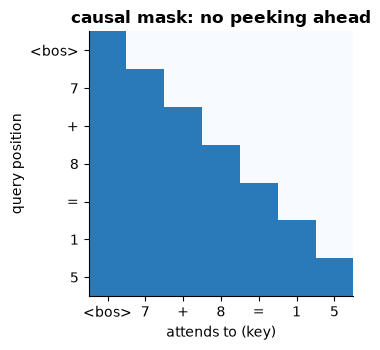

In [14]:
# Picture of the causal mask: row t = which positions token t may attend to.
labels = ["<bos>"] + list("7+8=15")
T = len(labels)
fig, ax = plt.subplots(figsize=(4, 3.6))
ax.imshow(torch.ones(T, T).tril().numpy(), cmap="Blues", vmin=0, vmax=1.4)
ax.set_xticks(range(T), labels); ax.set_yticks(range(T), labels); ax.grid(False)
ax.set_xlabel("attends to (key)"); ax.set_ylabel("query position"); ax.set_title("causal mask: no peeking ahead")
plt.tight_layout(); save_figure(fig, "04_causal_mask.png"); plt.show()

## 9. Text generation is a policy in a token MDP

| RL concept | Language model |
|---|---|
| state $s_t$ | prompt + tokens generated so far (the *prefix*) |
| action $a_t$ | next token (one of `vocab_size` choices) |
| policy $\pi_\theta(a_t\mid s_t)$ | softmax of the logits at the last position |
| transition | deterministic: append the token, $s_{t+1} = s_t \oplus a_t$ |
| episode end | the model emits `<eos>` (or hits the length limit) |
| reward | usually **only at the end**: is the answer right? (verifier, reward model, human) |

```mermaid
flowchart LR
    S0["s₀ = ‹bos›7+8="] -- "a₀ = '1'<br/>π = 0.6" --> S1["s₁ = ‹bos›7+8=1"]
    S1 -- "a₁ = '5'<br/>π = 0.4" --> S2["s₂ = ‹bos›7+8=15"]
    S2 -- "a₂ = ‹eos›<br/>π = 0.9" --> END(("end"))
    END -- "verifier: 15 == 7+8 → r = 1" --> R["reward on the LAST step only<br/>r₁ = r₂ = 0, r₃ = 1"]
```

With a reward only at the end and $\gamma = 1$, the reward-to-go of **every** token is the same number $R$.
REINFORCE for a language model therefore simplifies to

$$\nabla_\theta J \approx \frac1N\sum_i \big(R^i - b\big)\sum_{t\in\text{response}} \nabla_\theta\log\pi_\theta(y^i_t\mid x^i, y^i_{<t})
= \frac1N\sum_i \big(R^i - b\big)\,\nabla_\theta\log\pi_\theta(y^i\mid x^i).$$

It is **sequence log-probability × centred reward**. Notice how close this is to supervised fine-tuning:
SFT maximises $\log\pi_\theta(y^\star\mid x)$ for a *given* correct answer $y^\star$; REINFORCE maximises
$\log\pi_\theta(y\mid x)$ for the model's *own* samples, weighted by how good they turned out.

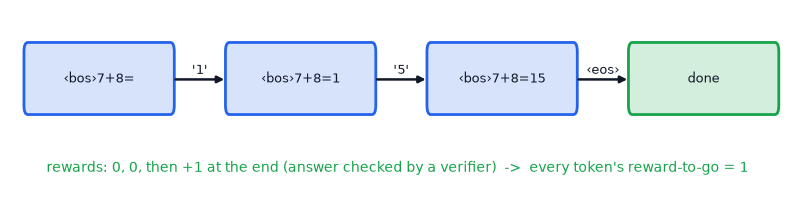

In [15]:
# A picture of one trajectory through the token MDP (saved as an image for slides/README).
fig, ax = plt.subplots(figsize=(10, 2.4)); ax.set_xlim(0, 10); ax.set_ylim(0, 1); ax.axis("off")
states = ["‹bos›7+8=", "‹bos›7+8=1", "‹bos›7+8=15", "done"]
acts = ["'1'", "'5'", "‹eos›"]   # actions (tokens) on the arrows
for k, st in enumerate(states):
    draw_box(ax, (0.2 + 2.6 * k, 0.45), 1.9, 0.35, st, COLORS["policy"] if k < 3 else COLORS["reward"], fontsize=9)
for k, a in enumerate(acts):
    draw_arrow(ax, (2.1 + 2.6 * k, 0.62), (2.8 + 2.6 * k, 0.62), text=a)
ax.text(5, 0.12, "rewards: 0, 0, then +1 at the end (answer checked by a verifier)  ->  every token's reward-to-go = 1",
        ha="center", fontsize=10, color=COLORS["reward"])
save_figure(fig, "04_token_mdp.png"); plt.show()

## 10. REINFORCE on the tiny GPT: learning to add

**Task.** Prompts `a+b=` with single digits $a, b$ (100 problems). Reward 1 if the sampled answer, followed by
`<eos>`, equals $a+b$, else 0. This is a **verifiable reward**, the same kind DeepSeek-R1 used for maths, just
microscopic.

**Why a short supervised warm-up first?** A randomly initialised model almost never samples a correct
answer, so every reward is 0, every centred reward is 0, and the gradient is exactly zero. Real LLM RL always
starts from a pretrained + SFT model for the same reason. We do only 40 SFT steps, so the model is far from
perfect (~20% accuracy) and RL has something to fix. Too much SFT would make the policy confident and
nearly deterministic, so almost every sample in a batch would get the same reward and leave nothing to learn
from.

In [16]:
task = AdditionTask(tok, digits=1, seed=0)
problems = task.all_problems()
PROMPT_LEN = 5                        # <bos> a + b =

torch.manual_seed(0)
lm = MiniGPT(tok.vocab_size)          # our from-scratch model
sft_hist = sft_train(lm, lambda: task.sft_batch(64, problems), steps=40, prompt_len=PROMPT_LEN)
acc_sft = evaluate(lm, task, problems)
print(f"after 40 SFT steps: loss {sft_hist[-1]:.3f}, greedy accuracy {acc_sft:.0%}")

after 40 SFT steps: loss 0.918, greedy accuracy 18%


(`generate`, `evaluate` and `sft_train` from rlkit work on our `MiniGPT` too: they only call
`model(ids, prefix_embeds=None)` and expect `(logits, hidden)` back.)

### Snippet 4: one REINFORCE step for a language model

> **Algorithm: REINFORCE for an LLM**
>
> 1. **Sample prompts** $x^1..x^B$ from the task.
> 2. **Generate** a response $y^i\sim\pi_\theta(\cdot\mid x^i)$ for each, token by token, at temperature $\tau$.
>    *Temperature > 1 flattens the distribution: more exploration, more chances to stumble on a correct
>    answer the greedy policy would miss.*
> 3. **Reward** each response with the verifier: $R^i\in\{0,1\}$.
> 4. **Re-score** the finished sequences in one parallel forward pass to get $\log\pi_\theta(y^i_t\mid x^i,y^i_{<t})$
>    for each response token. *Sampling is sequential; scoring is a single teacher-forced pass, which is why
>    this is affordable. We score with the same temperature we sampled with, so the gradient is for the
>    policy that actually produced the data.*
> 5. **Centre** the rewards with a baseline $b=\frac1B\sum_i R^i$.
> 6. **Loss** $= -\frac1B\sum_i (R^i-b)\sum_t \text{mask}_t\,\log\pi_\theta(y^i_t\mid\cdot)$. The mask zeroes
>    prompt and padding positions; the `<eos>` token is included (stopping is an action too).
> 7. **Step** the optimiser (with gradient clipping as a safety belt) and go back to 1.

In [17]:
def response_logprobs(model, seq, temperature):
    """log pi(token_t | prefix) for t = 1..T-1 (shape (B, T-1)), under the tempered policy."""
    logits, _ = model(seq)
    logp = F.log_softmax(logits[:, :-1] / temperature, dim=-1)
    return logp.gather(-1, seq[:, 1:].unsqueeze(-1)).squeeze(-1)


def lm_reinforce_step(model, opt, batch_size=128, temperature=1.5):
    prompts, answers = task.batch(batch_size, problems)                          # 1. prompts
    seq, mask = generate(model, prompts, max_new_tokens=task.answer_len + 1,
                         temperature=temperature)                                # 2. sample
    rewards = task.reward(seq, PROMPT_LEN, answers)                              # 3. verify
    logp = response_logprobs(model, seq, temperature)                            # 4. re-score
    mask = mask[:, 1:]                                                           #    align with logp
    advantage = rewards - rewards.mean()                                         # 5. baseline
    loss = -(advantage * (logp * mask).sum(1)).mean()                            # 6. surrogate
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()          # 7. update
    return rewards.mean().item()

### Training, while recording the model's beliefs for the GIF

Every 20 steps we snapshot, for **all** two-digit-answer problems, the probability of each possible
**first** answer token and of each **second** token given the correct first one (two batched forward passes).
After training we pick which prompts to show, so the GIF reflects what really happened rather than a
hand-picked example.

In [18]:
DIGITS_EOS = [tok.stoi[d] for d in "0123456789"] + [tok.EOS]
X_LABELS = list("0123456789") + ["⏎"]
TWO_DIGIT = [(p, a) for p, a in problems if len(a) == 2]       # e.g. 7+8=15: two decisions to get right

@torch.no_grad()
def snapshot(model):
    """(n_problems, 11) first-token probs and (n_problems, 11) second-token probs (given correct first)."""
    first_ctx = torch.tensor([tok.encode(p) for p, _ in TWO_DIGIT])
    second_ctx = torch.tensor([tok.encode(p + a[0]) for p, a in TWO_DIGIT])
    first = F.softmax(model(first_ctx)[0][:, -1], -1)[:, DIGITS_EOS]
    second = F.softmax(model(second_ctx)[0][:, -1], -1)[:, DIGITS_EOS]
    return first.numpy(), second.numpy()

opt = torch.optim.Adam(lm.parameters(), lr=1e-3)
reward_hist, acc_hist, snaps = [], [(0, acc_sft)], [(0, snapshot(lm), float("nan"))]
t0 = time.time()
for step in range(1, 601):
    reward_hist.append(lm_reinforce_step(lm, opt))
    if step % 20 == 0:
        snaps.append((step, snapshot(lm), np.mean(reward_hist[-20:])))
    if step % 50 == 0:
        acc_hist.append((step, evaluate(lm, task, problems)))
print(f"600 REINFORCE steps in {time.time() - t0:.0f}s")
print(f"greedy accuracy: {acc_sft:.0%} after SFT  ->  {acc_hist[-1][1]:.0%} after REINFORCE")
assert acc_hist[-1][1] > acc_sft + 0.3, "REINFORCE should clearly improve the policy"

600 REINFORCE steps in 28s
greedy accuracy: 18% after SFT  ->  78% after REINFORCE


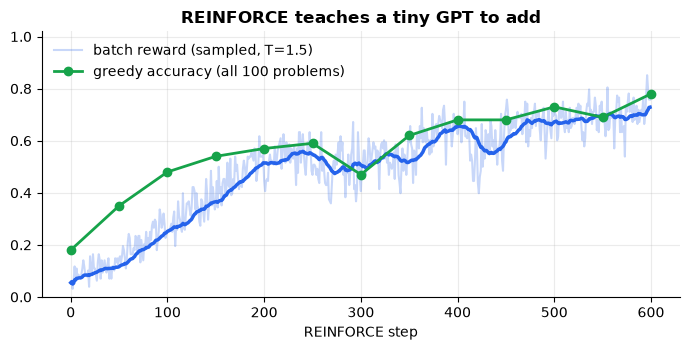

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(reward_hist, color=COLORS["policy"], alpha=0.25, label="batch reward (sampled, T=1.5)")
ax.plot(smooth(reward_hist, 25), color=COLORS["policy"], lw=2.5)
s_, a_ = zip(*acc_hist)
ax.plot(s_, a_, "o-", color=COLORS["reward"], lw=2, label="greedy accuracy (all 100 problems)")
ax.set_xlabel("REINFORCE step"); ax.set_ylim(0, 1.02); ax.set_title("REINFORCE teaches a tiny GPT to add"); ax.legend()
plt.tight_layout(); save_figure(fig, "04_lm_reinforce_curve.png"); plt.show()

The sampled reward (blue) stays below greedy accuracy (green) because we sample at temperature 1.5 on
purpose: exploration has a cost.

### GIF 2: the next-token distribution moving toward the right answer

Each row is one prompt: left, $\pi(\text{first answer token}\mid$ prompt$)$; right,
$\pi(\text{second token}\mid$ prompt + correct first digit$)$. Green bars are the correct tokens. Each frame is
20 REINFORCE updates later. The **top row** is the problem whose probability of the full correct answer rose
the most; the **bottom row** is the problem the final policy finds hardest. Watch the probability mass flow
into the green bars on top. That flow is $\nabla\log\pi \times (R-b)$ at work: rewarded tokens are pushed
up, the rest down. If the bottom row ends with all mass on a *wrong* bar, you are seeing **entropy collapse**:
the policy became confident before it ever sampled the right answer, so it gets no more learning signal for
that prompt. Entropy bonuses (nb 05/06), higher temperature and clip-higher (DAPO, nb 09) target this.

top row: ('5+5=', '10')  bottom row: ('8+4=', '12')  final p(correct answer): [1. 0.]


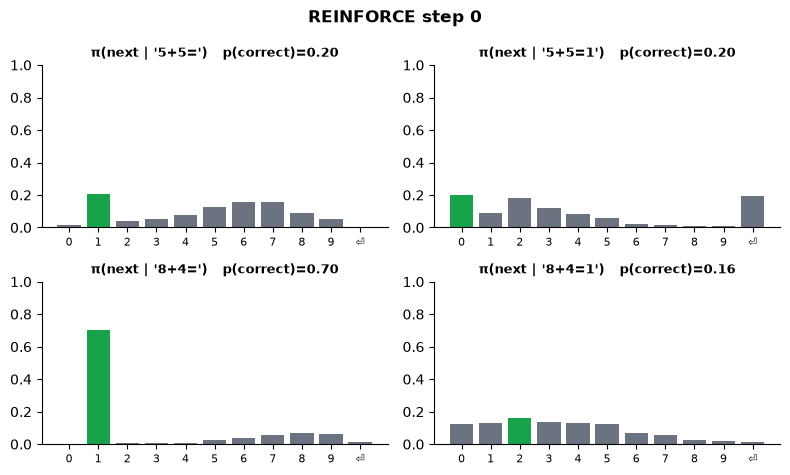


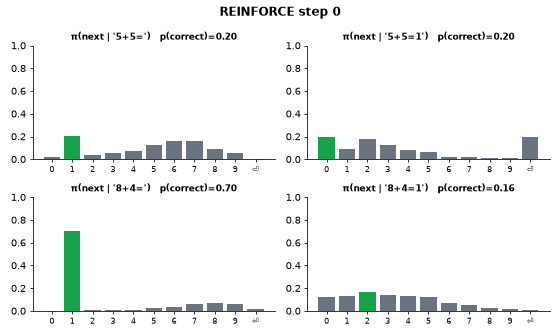

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/04_token_distribution.gif')

In [20]:
def p_full_answer(snap):
    first, second = snap
    idx = [(X_LABELS.index(a[0]), X_LABELS.index(a[1])) for _, a in TWO_DIGIT]
    return np.array([first[k, i] * second[k, j] for k, (i, j) in enumerate(idx)])

gain = p_full_answer(snaps[-1][1]) - p_full_answer(snaps[0][1])
show = [int(gain.argmax()), int(p_full_answer(snaps[-1][1]).argmin())]
WATCH = [TWO_DIGIT[k] for k in show]
print("top row:", WATCH[0], " bottom row:", WATCH[1],
      " final p(correct answer):", p_full_answer(snaps[-1][1])[show].round(2))

def draw_token_dist(fig, i):
    step, (first_all, second_all), batch_r = snaps[i]
    snap = [(first_all[k], second_all[k]) for k in show]
    fig.clf(); axes = fig.subplots(2, 2)
    for row, ((prompt, ans), (first, second)) in enumerate(zip(WATCH, snap)):
        for col, (p, target, ctx) in enumerate([(first, ans[0], prompt), (second, ans[1], prompt + ans[0])]):
            ax = axes[row, col]
            colors = [COLORS["reward"] if lab == target else COLORS["reference"] for lab in X_LABELS]
            ax.bar(range(11), p, color=colors)
            ax.set_ylim(0, 1); ax.set_xticks(range(11), X_LABELS, fontsize=8); ax.grid(False)
            ax.set_title(f"π(next | '{ctx}')   p(correct)={p[X_LABELS.index(target)]:.2f}", fontsize=9)
    rtxt = "" if np.isnan(batch_r) else f" · batch reward {batch_r:.2f}"
    fig.suptitle(f"REINFORCE step {step}{rtxt}", fontweight="bold")
    fig.tight_layout()

show_frame(draw_token_dist, 0, figsize=(8, 4.8))
Animator(draw_token_dist, n_frames=len(snaps), figsize=(8, 4.8), fps=4, dpi=70).save("04_token_distribution.gif")

## 11. Common pitfalls

| Symptom | Cause | Fix |
|---|---|---|
| gradient is exactly zero, nothing learns | every sample in the batch got the same reward (all 0 or all 1) | warm-start with SFT, raise temperature, harder/easier prompts (DAPO filters such batches, nb 09) |
| learning is noisy and slow | high variance of the Monte-Carlo estimate | reward-to-go, baselines, bigger batches, a learned value baseline (nb 05) |
| policy suddenly collapses after a good run | step too large; on-policy data becomes stale | lower LR, gradient clipping, a trust region (PPO/TRPO, nb 06) |
| reusing old samples breaks training | REINFORCE assumes samples come from the *current* policy | importance sampling + clipping (PPO), or resample every step |
| sign errors | optimisers minimise | the loss is **minus** $\log\pi\times$ advantage |
| reward leaks into gradient | forgot to detach the reward/advantage | rewards/advantages are constants (`torch.no_grad` or `.detach()`) |
| the model learns to stop early / ramble | `<eos>` masked out of the loss, or length-dependent rewards | include `<eos>` in the response mask, watch length statistics |

## 12. How this connects to LLM/VLM training

* **Every** modern LLM RL algorithm is a refinement of $\sum_t \nabla\log\pi(y_t\mid\cdot)\,\hat A_t$:
  PPO-RLHF (nb 07) uses a learned critic for $\hat A_t$ and a clipped ratio; GRPO / RLOO (nb 09) use the
  mean reward of several samples **of the same prompt** as the baseline; ReMax uses the greedy answer's
  reward as the baseline.
* The structure "sample with the inference engine, re-score with the trainer" is literally how large systems
  are built (vLLM/SGLang for rollouts, FSDP/Megatron for the log-prob + gradient pass), see nb 13.
* For a **VLM** nothing changes: the image only enters the *state* (as prefix tokens), and actions are still
  text tokens, so the identical loss trains it (nb 12).

## 13. Cheat sheet

| Concept | Formula | Code |
|---|---|---|
| objective | $J(\theta)=\mathbb{E}_{\tau\sim\pi_\theta}[R(\tau)]$ | average episode return |
| log-derivative trick | $\nabla p = p\,\nabla\log p$ | - |
| policy gradient | $\mathbb{E}\big[\sum_t\nabla\log\pi(a_t\mid s_t)\,R(\tau)\big]$ | `-(logp * R).sum()` |
| reward-to-go | $G_t=\sum_{t'\ge t}\gamma^{t'-t}r_{t'+1}$ | `returns_to_go(rewards, gamma)` |
| baseline | $\mathbb{E}[\nabla\log\pi\,b(s)]=0$ | `G - G.mean()` |
| LLM REINFORCE | $(R-b)\,\nabla\log\pi(y\mid x)$ | `-(adv * (logp*mask).sum(1)).mean()` |
| exploration | temperature $\tau$ | `softmax(logits / tau)` |

**Key papers:** Williams (1992) *Simple statistical gradient-following algorithms for connectionist RL*
(REINFORCE); Sutton, McAllester, Singh & Mansour (2000) *Policy gradient methods for RL with function
approximation* (policy-gradient theorem). **Next:** notebook 05 replaces the crude batch-mean baseline with
a learned **critic** and introduces **GAE**, the advantage estimator inside PPO.